# 03 · Root cause analysis

**Question:** which process parameters, reactors, plants or operating regimes explain the reduced shelf-life stability?

Input: the clean table from phase 2. Methods are standard on purpose: group means with 95% confidence intervals, control charts, comparisons against an unaffected control group, simple models used to *separate* factors. A conclusion is trusted only when independent pieces of evidence agree, and causes are confirmed with the plant, not by the data alone.

| Step | Question | Hypotheses |
|---|---|---|
| 3.1 | The May 8 event: when, where, how big, what changed? | H1 |
| 3.2 | Process window: which conditions lower stability outside the event? | H2–H5 |
| 3.3 | Readable rules: can it be written as rules engineers trust? | all |
| 3.4 | Plants and reactors: the plant, or how it operates? | all |
| 3.5 | Synthesis: how much does each cause explain, and how to confirm it? | all |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import importlib
import numpy as np
import pandas as pd
from fragrance import config, plots, rootcause

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

df = pd.read_parquet(config.CLEAN_PARQUET)   # produced by notebooks/02_cleaning.ipynb
y = df[config.TARGET]
sensors = config.CLEAN_SENSOR_COLS
print(f"{len(df):,} batches, {df['reactor'].nunique()} reactors, {df['event_time'].dt.normalize().nunique()} days")

259,200 batches, 37 reactors, 90 days


## 3.1 · The May 8 event (H1)
The audit (01 Q6) already located the drop: three Plant-04 reactors, from 2023-05-08, while no other reactor changes. This step measures it and looks for what changed.

Groups used throughout this step:
- **affected:** Plant-04 reactors R03, R07, R08;
- **control:** the other five Plant-04 reactors (same plant, same raw-material supply, same staff, same weeks);
- **after:** batches from 2023-05-08 00:00.

In [2]:
EVENT = pd.Timestamp("2023-05-08")
AFFECTED = ["Plant-04/R03", "Plant-04/R07", "Plant-04/R08"]
affected = df["reactor"].isin(AFFECTED)
control = df["plant_location"].eq("Plant-04") & ~affected
after = df["event_time"] >= EVENT

### 3.1a · When exactly
Only batches with a real time of day (`has_time`). Last batch before and first batch after midnight on May 8, per affected reactor.

In [3]:
timed = df[affected & df["has_time"]].sort_values("event_time")
last_before = timed[timed["event_time"] < EVENT].groupby("reactor").tail(1)
first_after = timed[timed["event_time"] >= EVENT].groupby("reactor").head(1)
cols = ["reactor", "event_time", "mixing_torque_nm", config.TARGET]
pd.concat([last_before[cols].assign(side="last before"), first_after[cols].assign(side="first after")]).sort_values(["reactor", "event_time"])

,reactor,event_time,mixing_torque_nm,stability_months,side
86570,Plant-04/R03,2023-05-07 23:24:00,12.091260,23.881099,last before
209084,Plant-04/R03,2023-05-08 00:02:00,10.342695,18.033482,first after
178617,Plant-04/R07,2023-05-07 23:46:30,NaN,20.716243,last before
112292,Plant-04/R07,2023-05-08 00:19:00,11.003125,19.017247,first after
80464,Plant-04/R08,2023-05-07 23:57:00,12.465300,23.493300,last before
131091,Plant-04/R08,2023-05-08 00:40:00,11.228194,18.460253,first after


### 3.1b · Control charts
A Shewhart control chart plots a quantity over time against a centre line and limits at ± 3 standard deviations, computed on a **baseline** period when the process was considered normal (here April 1 – May 7, shaded). If nothing changes, a point outside the limits happens about 3 times in 1,000. Points are the daily means of each affected reactor; limits are computed from the baseline daily means of the three.

mean stability (months): centre 21.85, limits [21.10, 22.60] | days out of limits: before 1%, after 100%
mean mixing torque (N·m): centre 12.02, limits [11.91, 12.13] | days out of limits: before 1%, after 100%


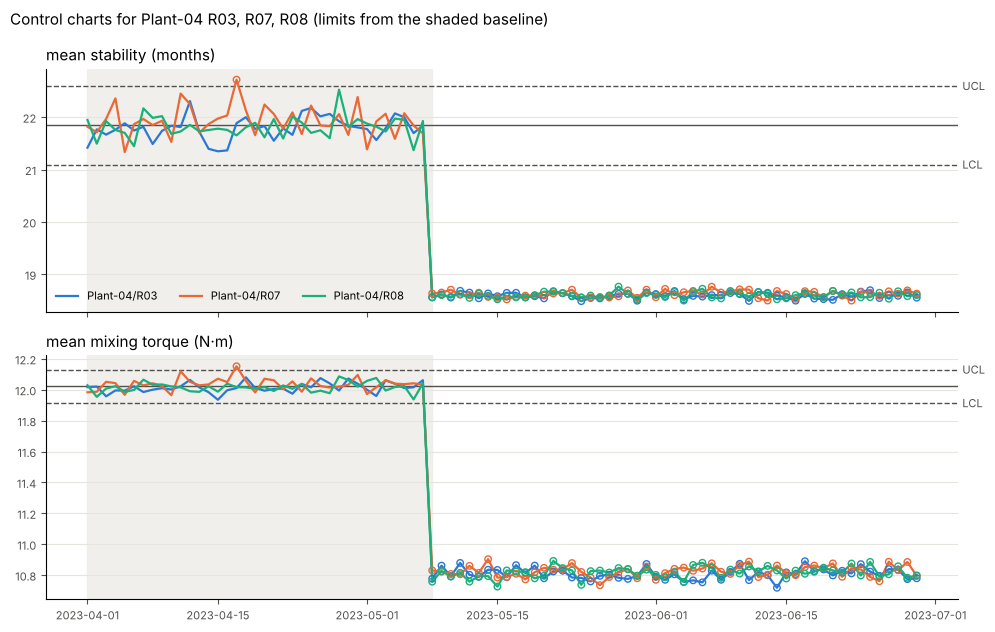

In [4]:
def chart_panel(value):
    table = rootcause.daily_mean(df[affected], value, "reactor")
    baseline = table.index < EVENT
    limits = rootcause.control_limits(table[baseline].stack(), pd.Series(True, index=table[baseline].stack().index))
    return table, limits

panels = {"mean stability (months)": chart_panel(config.TARGET),
          "mean mixing torque (N·m)": chart_panel("mixing_torque_nm")}
for name, (table, lim) in panels.items():
    out_after = ((table[table.index >= EVENT] < lim["lcl"]) | (table[table.index >= EVENT] > lim["ucl"])).mean().mean()
    out_before = ((table[table.index < EVENT] < lim["lcl"]) | (table[table.index < EVENT] > lim["ucl"])).mean().mean()
    print(f"{name}: centre {lim['centre']:.2f}, limits [{lim['lcl']:.2f}, {lim['ucl']:.2f}] | days out of limits: before {out_before:.0%}, after {out_after:.0%}")
plots.control_charts(panels, "Control charts for Plant-04 R03, R07, R08 (limits from the shaded baseline)",
                     baseline_end=EVENT, filename="rca_control_charts_event.png");

### 3.1c · Is the drop tied to the event? Comparison with a control group
If something plant-wide had happened on May 8 (a new raw-material lot for the whole plant, a seasonal effect), the control reactors would move too. The **net effect** is the affected group's change minus the control group's change (in econometrics this is called a *difference-in-differences*).

In [5]:
rootcause.before_after(df, config.TARGET, {"affected (R03, R07, R08)": affected, "control (other Plant-04)": control}, after).round(3)

,before,after,change,ci_low,ci_high,n_before,n_after
"affected (R03, R07, R08)",21.846,18.608,-3.239,-3.281,-3.197,9227.0,13145.0
control (other Plant-04),21.790,21.811,0.021,-0.023,0.064,13731.0,19755.0


In [6]:
rootcause.diff_in_diff(df, config.TARGET, affected, control, after).round(3).rename("net effect on stability (months)")

effect    -3.260
ci_low    -3.320
ci_high   -3.199
Name: net effect on stability (months), dtype: float64

### 3.1d · What changed in the process: the event's fingerprint
The same net-effect comparison for every sensor, in its own unit and in standard deviations of normal operation. A large value means the sensor moved far outside its usual variation.

In [7]:
rootcause.sensor_shift(df, sensors, affected, control, after).round(4).sort_values("effect_in_sd", key=abs, ascending=False)

,effect,ci_low,ci_high,effect_in_sd
mixing_torque_nm,-1.2029,-1.2138,-1.1920,-4.1484
density_g_cm3,0.0049,0.0045,0.0053,0.4246
ph_level,0.1037,0.0932,0.1142,0.3559
reaction_temperature_celsius,0.1029,-0.0300,0.2358,0.0282
vessel_pressure_bar,-0.0036,-0.0097,0.0026,-0.0209
refractive_index,-0.0002,-0.0006,0.0002,-0.0154
mass_flow_rate_kg_h,0.2719,-1.0532,1.5969,0.0074


### 3.1e · Can the data tell whether lower torque *caused* the drop?
To isolate torque, we would compare event batches with normal batches **at the same torque**. Check how much the torque ranges overlap:

In [8]:
event_rows = affected & after
print("torque in event batches:      ", df.loc[event_rows, "mixing_torque_nm"].quantile([0, .5, 1]).round(2).tolist())
print("torque in all other batches:  ", df.loc[~event_rows, "mixing_torque_nm"].quantile([0, .5, 1]).round(2).tolist())
overlap = df.loc[event_rows, "mixing_torque_nm"] >= df.loc[~event_rows, "mixing_torque_nm"].min()
print(f"event batches with a torque also seen outside the event: {overlap.mean():.1%}")

torque in event batches:       [10.04, 10.81, 11.62]
torque in all other batches:   [11.44, 12.0, 12.56]
event batches with a torque also seen outside the event: 2.7%


## 3.1 · Conclusions
- **Where:** only three of 37 reactors are affected: Plant-04 R03, R07 and R08. Every other reactor, including the five others in Plant-04, is stable all quarter (01 Q6).
- **When:** a step change at **midnight on 2023-05-08**, the same night in all three reactors. The last normal batches are at 23:24–23:57 on May 7, the first low ones at 00:02–00:40 on May 8. The level then stays low until the end of the data: no recovery, no drift.
- **How big:** −3.24 months (21.85 → 18.61, 95% CI −3.28 to −3.20). The control reactors moved +0.02 (CI −0.02 to +0.06), so the **net effect is −3.26 months (CI −3.32 to −3.20)**. Nothing plant-wide or seasonal explains it.
- **Control charts:** before May 8, 1% of days fall outside the ± 3σ limits (as expected by chance); from May 8, **100% of days** fall below the lower limit, for both stability and torque. A quality team monitoring daily torque with this chart would have caught the event on day one.
- **Fingerprint:** mixing torque fell by 1.20 N·m, which is **4.1 standard deviations** of normal operation. Density (+0.4 SD) and pH (+0.4 SD) rose slightly. Temperature, pressure, refractive index and mass flow did not change (their confidence intervals include zero).
- **What the data cannot say:** event batches run at 10.0–11.6 N·m, a torque that practically never occurs elsewhere (2.7% overlap). So we cannot separate "the event lowered torque, and lower torque lowered stability" from "something (e.g. a different raw-material lot or a recipe change) lowered both". **The plant has to answer:** what changed on the night of May 7–8 in these three reactors (maintenance on the agitators, a setpoint or recipe change, a raw-material lot shared by the three, a shift change)?
- Business impact: 13,145 batches (5.1% of production) since May 8, about −3.3 months of shelf life each, at a rate of ~250 batches per day while it continues.

## 3.2 · The process window outside the event (H2–H5)
Which operating conditions lower stability in the other ~95% of production?

Data for this step: all batches **except** the May 8 event batches (their torque is far outside the usual range and would dominate every curve) and except the 5,344 records with no sensor data. *Low stability* = below 20 months, the Technical-grade cut-off.

In [9]:
event = affected & after
window = df[~event & ~df["all_sensors_missing"]]
yw = window[config.TARGET]
low = yw < 20
print(f"{len(window):,} batches, {low.mean():.1%} below 20 months")

240,979 batches, 23.0% below 20 months


### 3.2a · Are the sensors related to each other?
If two sensors moved together, the curve of one would partly show the effect of the other (confounding). The largest correlation between two different sensors:

In [10]:
corr = window[sensors].corr()
off_diag = corr.where(~pd.DataFrame(np.eye(len(sensors), dtype=bool), index=sensors, columns=sensors)).abs()
print(f"largest |correlation| between two sensors: {off_diag.max().max():.3f}")

largest |correlation| between two sensors: 0.019


### 3.2b · The shape of each effect
Mean stability (with 95% CI band) in each tenth of each sensor's values. Dashed lines: the statement's normal range, where it falls inside the plotted values. Shared y axis, so the panels are directly comparable.

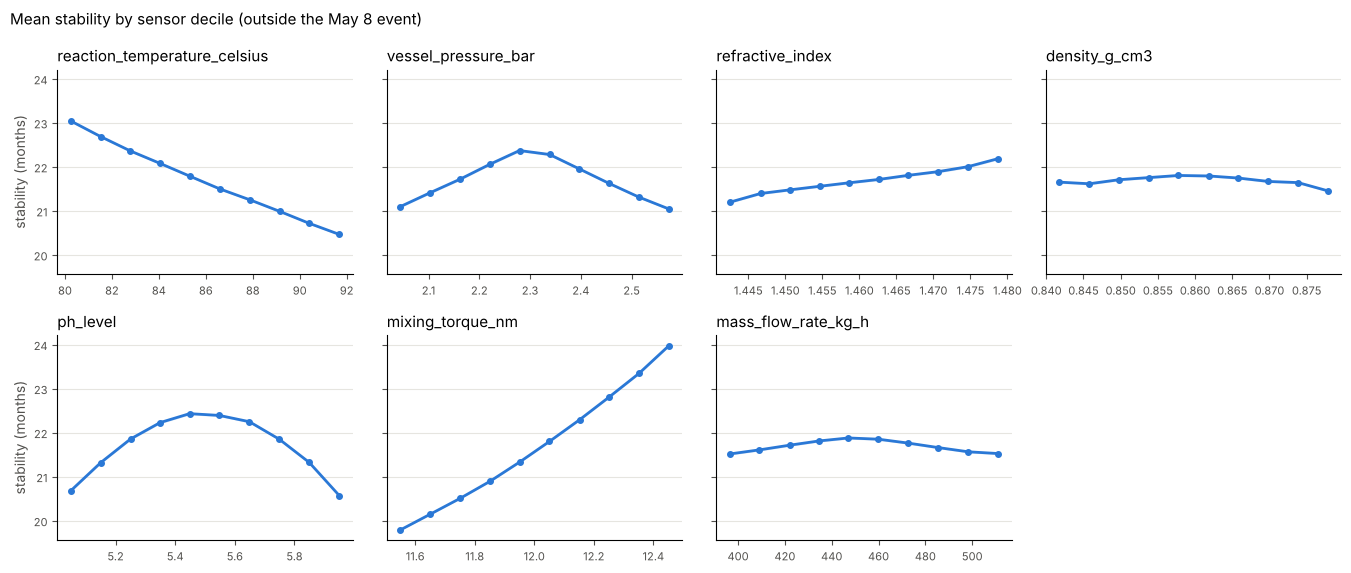

In [11]:
curves = {s: rootcause.binned_curve(window, s, config.TARGET) for s in sensors}
plots.curve_grid(curves, "Mean stability by sensor decile (outside the May 8 event)", "stability (months)",
                 ranges={config.TEMP_CELSIUS: config.NORMAL_RANGES[config.TEMP_VALUE],
                         **{s: config.NORMAL_RANGES[s] for s in sensors if s in config.NORMAL_RANGES}},
                 filename="rca_stability_by_sensor.png");

In [12]:
shapes = pd.DataFrame({s: rootcause.effect_shape(c) for s, c in curves.items()}).T
shapes["swing"] = shapes["swing"].astype(float).round(2)
shapes.sort_values("swing", ascending=False)

,swing,best_at,shape
mixing_torque_nm,4.19,12.45216,increasing
reaction_temperature_celsius,2.58,80.2439,decreasing
ph_level,1.86,5.44824,peaked
vessel_pressure_bar,1.33,2.27914,peaked
refractive_index,0.99,1.478778,increasing
mass_flow_rate_kg_h,0.36,447.1068,peaked
density_g_cm3,0.35,0.857749,peaked


### 3.2c · Low vs normal batches: why comparing means is not enough
The textbook comparison: mean of each sensor in low-stability batches minus normal batches, with 95% CI, and the same difference in standard deviations of the sensor so sensors are comparable.

In [13]:
rows = {}
for s in sensors:
    d = rootcause.diff_ci(window.loc[low, s], window.loc[~low, s])
    rows[s] = {**d.to_dict(), "diff_in_sd": d["diff"] / window[s].std()}
pd.DataFrame(rows).T.sort_values("diff_in_sd", key=abs, ascending=False).round(4)

,diff,ci_low,ci_high,diff_in_sd
mixing_torque_nm,-0.3442,-0.3463,-0.3422,-1.1808
reaction_temperature_celsius,2.6540,2.6211,2.6868,0.7181
refractive_index,-0.0029,-0.0030,-0.0028,-0.2472
ph_level,0.0112,0.0079,0.0145,0.0385
density_g_cm3,0.0004,0.0002,0.0005,0.0306
vessel_pressure_bar,0.0042,0.0024,0.0060,0.0246
mass_flow_rate_kg_h,0.5443,0.1714,0.9173,0.0147


pH and pressure look irrelevant here (≈ 0.03 SD), yet their curves above swing by 1.4–1.9 months. Their effect is **peaked**: low-stability batches sit at *both* ends, so the "too low" and "too high" batches cancel out in a mean. The right comparison for a peaked sensor is the **distance from its best value**:

In [14]:
rows = {}
for s in shapes.index[shapes["shape"] == "peaked"]:
    dist = (window[s] - shapes.loc[s, "best_at"]).abs()
    d = rootcause.diff_ci(dist[low], dist[~low])
    rows[s] = {"best_at": shapes.loc[s, "best_at"], **d.to_dict(), "diff_in_sd": d["diff"] / dist.std()}
pd.DataFrame(rows).T.round(4)

,best_at,diff,ci_low,ci_high,diff_in_sd
vessel_pressure_bar,2.2791,0.0340,0.0331,0.0348,0.3869
density_g_cm3,0.8577,0.0005,0.0004,0.0006,0.0831
ph_level,5.4482,0.0906,0.0891,0.0920,0.5997
mass_flow_rate_kg_h,447.1068,2.1482,1.9597,2.3368,0.1121


**Does the choice of 20 months matter?** *Low* = below 20 months is exactly `purity_grade == "Technical Grade"` (the business's lowest tier, and practically the bottom quarter of production). Using the grade to *define the groups* is fine; it is only forbidden as a model input. Re-running the comparison with the oxidation-risk threshold (21 months) and with the worst 10% of batches:

In [15]:
thresholds = {"< 20 (Technical grade)": yw < 20, "< 21 (oxidation risk)": yw < 21, "worst 10%": yw < yw.quantile(0.10)}
assert (window["purity_grade"].eq("Technical Grade") == (yw < 20)).all()
pd.DataFrame({name: {s: rootcause.diff_ci(window.loc[m, s], window.loc[~m, s])["diff"] / window[s].std() for s in sensors}
              for name, m in thresholds.items()}).round(2)

,< 20 (Technical grade),< 21 (oxidation risk),worst 10%
reaction_temperature_celsius,0.72,0.66,0.83
vessel_pressure_bar,0.02,0.03,0.03
refractive_index,-0.25,-0.23,-0.30
density_g_cm3,0.03,0.03,0.04
ph_level,0.04,0.02,0.07
mixing_torque_nm,-1.18,-1.16,-1.23
mass_flow_rate_kg_h,0.01,0.01,0.01


Same ranking and nearly the same sizes under all three definitions: the conclusions do not depend on where *low* starts.

### 3.2d · Do temperature and torque interact?
Mean stability for each combination of temperature and torque fifths. Parallel rows = the two effects simply add up; rows that fan out = interaction.

torque effect (highest − lowest fifth) per temperature row: [4.19, 4.01, 3.7, 3.4, 3.03]
largest deviation from a purely additive table: 0.36 months


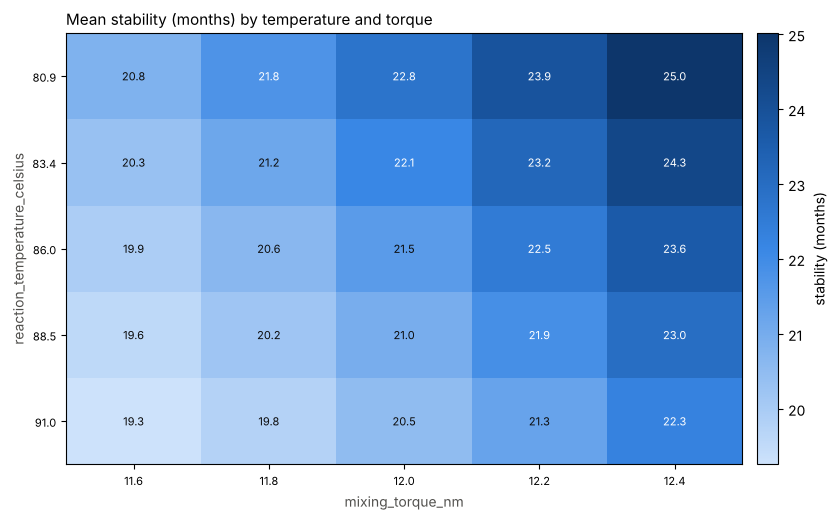

In [16]:
tt = rootcause.two_way_means(window, config.TEMP_CELSIUS, "mixing_torque_nm", config.TARGET)
plots.value_heatmap(tt, "Mean stability (months) by temperature and torque", "stability (months)",
                    filename="rca_temperature_torque.png")
gain = tt.iloc[:, -1] - tt.iloc[:, 0]
print("torque effect (highest − lowest fifth) per temperature row:", gain.round(2).tolist())
print(f"largest deviation from a purely additive table: {rootcause.additivity_gap(tt):.2f} months")

### 3.2e · H5: low pressure in Plant-02
All 509 readings below 2 bar come from Plant-02. A small subgroup, so here a test is informative: Welch's t-test (means) and Mann-Whitney (ranks). Two comparisons: against the rest of Plant-02, and against Plant-02 batches just above the limit (2.00–2.05 bar).

In [17]:
p2 = window[window["plant_location"].eq("Plant-02")]
pressure = p2["vessel_pressure_bar"]
below = p2.loc[pressure < 2, config.TARGET]
pd.DataFrame({
    "vs rest of Plant-02": rootcause.group_test(below, p2.loc[pressure >= 2, config.TARGET]),
    "vs Plant-02 at 2.00–2.05 bar": rootcause.group_test(below, p2.loc[pressure.between(2.0, 2.05), config.TARGET]),
}).T.round(4)

,diff,ci_low,ci_high,p_welch,p_mannwhitney,n_a,n_b
vs rest of Plant-02,-0.8313,-0.9663,-0.6962,0.0000,0.0000,509.0,31597.0
vs Plant-02 at 2.00–2.05 bar,-0.1645,-0.3104,-0.0185,0.0275,0.0333,509.0,2782.0


In [18]:
window.groupby("plant_location")["vessel_pressure_bar"].describe()[["mean", "min", "max"]].round(3)

,mean,min,max
plant_location,,,
Plant-01,2.321,2.022,2.620
Plant-02,2.284,1.989,2.580
Plant-03,2.316,2.018,2.614
Plant-04,2.300,2.000,2.596
Plant-05,2.309,2.014,2.609


## 3.2 · Conclusions
- **Sensors are independent of each other** (largest |r| = 0.02), so each curve shows that sensor's own association with stability, not another sensor's in disguise.
- **Four process conditions matter**, ranked by how far stability moves between their best and worst tenth:

| Sensor | Shape | Swing | Best | Reading |
|---|---|---|---|---|
| Mixing torque | increasing | 4.2 months | highest observed (~12.5 N·m) | more agitation effort, more stability |
| Temperature | decreasing | 2.6 months | lowest observed (~80 °C) | hotter reactions, less stability |
| pH | **peaked** | 1.9 months | ~5.45 | both too acidic and not acidic enough hurt |
| Pressure | **peaked** | 1.3 months | ~2.28 bar | an optimum window |

  Refractive index (+1.0) is a fingerprint of the mixture's composition, a *consequence* of the process rather than a setting an operator can turn. Density and mass flow barely matter (≈ 0.35 months).
- **The statement's normal ranges are not the optimal ranges.** pH 5.05 is "normal" yet costs ~1.8 months versus pH 5.45; pressure 2.05 bar is "normal" yet costs ~1.3 months versus 2.28 bar. Narrower target windows are a concrete, low-cost recommendation, to be confirmed by a trial.
- **Comparing means misses peaked effects.** In the textbook low-vs-normal table, pH and pressure look irrelevant (0.02–0.04 SD), because low-stability batches sit at both ends and cancel out. Measured as distance from the best value, they separate clearly (pH 0.60 SD, pressure 0.39 SD). This is why we look at curves before summarising with a single number.
- **Temperature and torque add up, with a mild interaction:** raising torque from its lowest to its highest fifth gains 4.2 months at ~81 °C but 3.0 months at ~91 °C. The largest departure from purely additive effects is 0.36 months, small next to the main effects (2.6–4.2).
- **H5 is not a separate problem.** The 509 low-pressure batches (all Plant-02) are 0.83 months below the rest of Plant-02 (CI −0.97 to −0.70), but only 0.16 months (CI −0.31 to −0.02, Welch p = 0.03) below Plant-02 batches at 2.00–2.05 bar. They are simply the low end of the pressure curve: Plant-02 runs ~0.03 bar lower than the other plants, so its lowest readings fall just under 2 bar. *The p-value is informative here because the group is small: 509 batches.*

## 3.3 · Readable rules and an independent cross-check
Two complementary models, both used to **explain**, not to predict (prediction is phase 4):
- a **shallow decision tree**: a handful of if-then rules an engineer can read and challenge;
- **gradient boosting (LightGBM) + SHAP**: a flexible model that finds shapes and interactions on its own, explained with SHAP values (the contribution of each sensor to each prediction, in months). If it finds the same drivers, shapes and event as the simple analysis of 3.1–3.2, without being told about them, those conclusions are much harder to challenge.

Data: every batch with sensor data, **including** the May 8 event (the models must find it unaided). Inputs: the 7 sensors only. Plants and reactors are left out on purpose: the question here is which *process conditions* matter (plants come in 3.4). A random 25% of batches is held out to check that the rules hold on batches the model has not seen.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

data = df[~df["all_sensors_missing"]]
X, y_all = data[sensors], data[config.TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.25, random_state=42)
print(f"train {len(X_train):,} | test {len(X_test):,} batches")

train 190,392 | test 63,464 batches


### 3.3a · How deep should the tree be?
Each extra level doubles the number of rules. R² on the held-out batches (share of the variation in stability explained):

In [20]:
depths = {}
for depth in [1, 2, 3, 4, 6]:
    t = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=2000, random_state=42).fit(X_train, y_train)
    depths[depth] = {"rules": t.get_n_leaves(), "R2_train": t.score(X_train, y_train), "R2_test": t.score(X_test, y_test)}
pd.DataFrame(depths).T.round(3)

,rules,R2_train,R2_test
1,2.0,0.328,0.330
2,4.0,0.453,0.455
3,8.0,0.543,0.545
4,16.0,0.586,0.587
6,42.0,0.655,0.653


Depth 3 gives 8 rules and explains about half of the variation; depth 4 doubles the rules for +0.04. Train and test R² are equal, so the rules are not memorising noise. `min_samples_leaf=2000` stops any rule from resting on a handful of batches.

In [21]:
tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=2000, random_state=42).fit(X_train, y_train)
rules = rootcause.tree_rules(tree, sensors, X, y_all)
rules.style.format({"batches": "{:,}", "mean_stability": "{:.1f}", "share_below_20": "{:.0%}"})

,rule,batches,mean_stability,share_below_20
0,mixing_torque_nm ≤ 11.32,"11,054",18.5,99%
1,11.32 < mixing_torque_nm ≤ 11.74,"54,554",20.0,57%
2,11.74 < mixing_torque_nm ≤ 12.03 AND reaction_temperature_celsius > 85.04,"49,939",20.6,36%
3,12.03 < mixing_torque_nm ≤ 12.29 AND reaction_temperature_celsius > 86.19,"25,849",21.5,13%
4,11.74 < mixing_torque_nm ≤ 12.03 AND reaction_temperature_celsius ≤ 85.04,"33,016",21.9,10%
5,mixing_torque_nm > 12.29 AND reaction_temperature_celsius > 86.19,"20,996",22.7,2%
6,12.03 < mixing_torque_nm ≤ 12.26 AND reaction_temperature_celsius ≤ 86.19,"28,535",22.9,2%
7,mixing_torque_nm > 12.26 AND reaction_temperature_celsius ≤ 86.19,"29,913",24.3,0%


The same eight rules drawn as a tree, so they can be read top-down like a checklist.

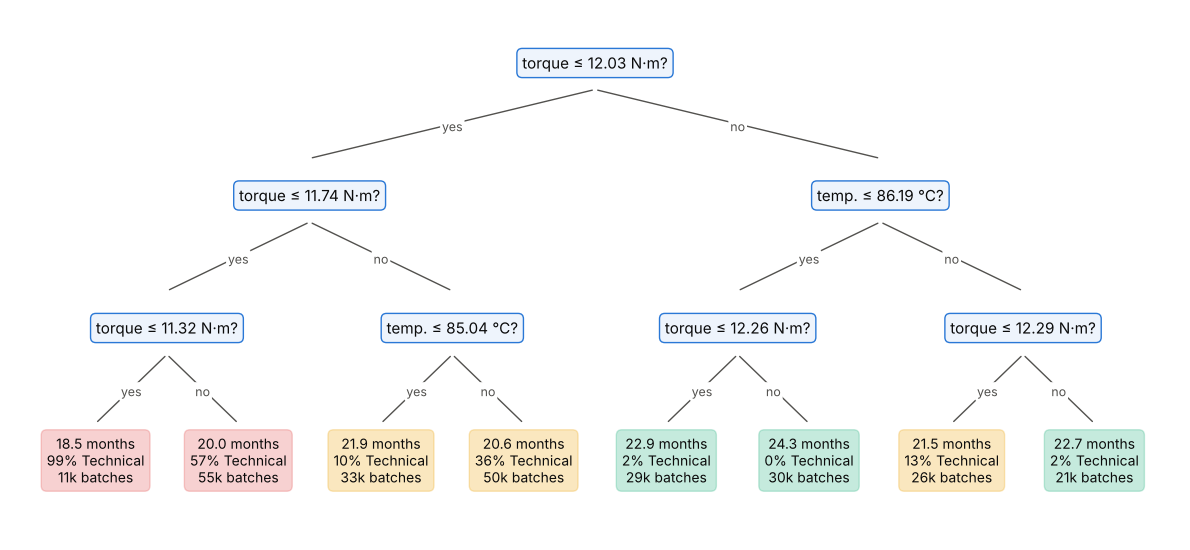

In [22]:
plots.tree_diagram(tree, X, y_all, {"mixing_torque_nm": ("torque", "N·m"), config.TEMP_CELSIUS: ("temp.", "°C")},
                   filename="rca_decision_tree.png");

In [23]:
event_rows = (affected & after)[data.index]
leaf = pd.Series(tree.apply(X), index=X.index)
worst_leaf = leaf[y_all.index][y_all.groupby(leaf).transform("mean") == y_all.groupby(leaf).mean().min()]
print(f"batches in the worst rule: {len(worst_leaf):,}, of which from the May 8 event: {event_rows[worst_leaf.index].mean():.0%}")
print(f"May 8 event batches that land in the worst rule: {event_rows[worst_leaf.index].sum() / event_rows.sum():.0%}")

batches in the worst rule: 11,054, of which from the May 8 event: 100%
May 8 event batches that land in the worst rule: 86%


### 3.3b · Gradient boosting as a cross-check
Default-like settings, no tuning: the goal is a flexible model that agrees or disagrees with the simple analysis, not the best predictor.

In [24]:
import lightgbm as lgb

gbm = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1)
gbm.fit(X_train, y_train)
pd.DataFrame({"R2_test": [tree.score(X_test, y_test), gbm.score(X_test, y_test)],
              "MAE_test (months)": [(tree.predict(X_test) - y_test).abs().mean(), (gbm.predict(X_test) - y_test).abs().mean()]},
             index=["tree, depth 3", "LightGBM"]).round(3)

,R2_test,MAE_test (months)
"tree, depth 3",0.545,1.093
LightGBM,0.790,0.739


### 3.3c · Which sensors does the flexible model rely on? (SHAP)
A SHAP value says how much a sensor pushed one batch's prediction up or down from the average, in months; the mean of its absolute value is the sensor's global importance. Computed on 10,000 held-out batches. SHAP explains the *model*; it describes the process only as far as the model is right, which is why it is compared with the curves of 3.2. Here the sensors are independent of each other (3.2a), which keeps SHAP attributions clean (correlated inputs can share credit arbitrarily).

In [25]:
import shap

X_shap = X_test.sample(10_000, random_state=42)
shap_values = shap.TreeExplainer(gbm).shap_values(X_shap)
importance = rootcause.shap_summary(shap_values, X_shap)
importance.join(shapes["swing"].rename("swing in 3.2 (months)")).round(3)

,mean_abs_shap,share,swing in 3.2 (months)
mixing_torque_nm,1.162,0.389,4.19
reaction_temperature_celsius,0.617,0.206,2.58
ph_level,0.509,0.170,1.86
vessel_pressure_bar,0.350,0.117,1.33
refractive_index,0.191,0.064,0.99
mass_flow_rate_kg_h,0.100,0.033,0.36
density_g_cm3,0.061,0.020,0.35


### 3.3d · Do the shapes match?
SHAP dependence plots: each dot is a batch; x = the sensor's value, y = its contribution to the prediction. May 8 event batches in orange.

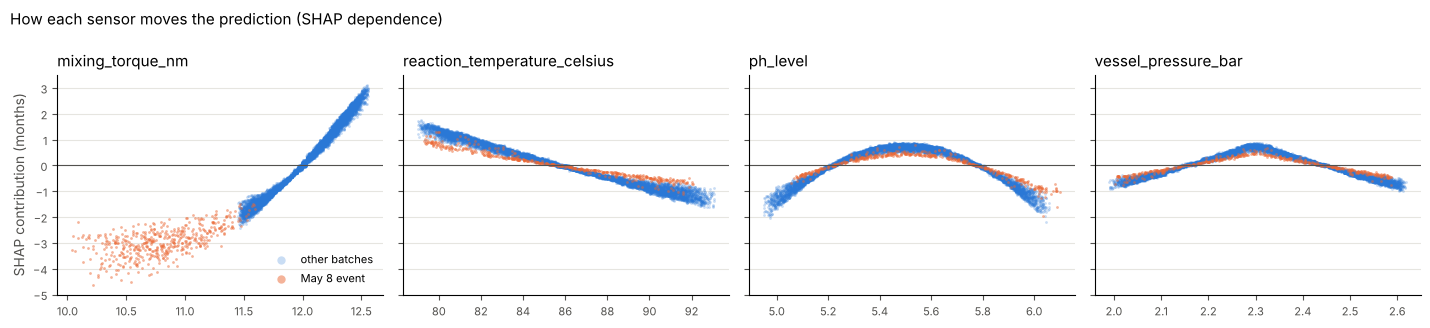

In [26]:
plots.dependence_grid(X_shap, shap_values, ["mixing_torque_nm", config.TEMP_CELSIUS, "ph_level", "vessel_pressure_bar"],
                      "How each sensor moves the prediction (SHAP dependence)",
                      highlight=event_rows[X_shap.index], highlight_label="May 8 event",
                      filename="rca_shap_dependence.png");

In [27]:
ev = event_rows[X_shap.index].to_numpy()
contrib = pd.DataFrame(shap_values, columns=sensors, index=X_shap.index)
pd.DataFrame({"May 8 event batches": contrib[ev].mean(), "other batches": contrib[~ev].mean()}).round(2).sort_values("May 8 event batches")

,May 8 event batches,other batches
mixing_torque_nm,-2.73,0.14
vessel_pressure_bar,-0.02,-0.00
ph_level,-0.02,0.00
density_g_cm3,-0.01,0.00
mass_flow_rate_kg_h,-0.00,-0.00
refractive_index,0.01,0.00
reaction_temperature_celsius,0.04,0.01


## 3.3 · Conclusions
- **Eight rules explain about half of the variation** (R² 0.54 on held-out batches, the same as on training batches). They use only torque and temperature:
  - **torque ≤ 11.32 N·m → 18.5 months, 99% Technical grade.** This rule *is* the May 8 event, found without being told: all 11,054 batches in it come from the event, and 86% of event batches land in it.
  - torque 11.32–11.74 → 20.0 months, 57% Technical;
  - torque 11.74–12.03 and temperature > 85 °C → 20.6 months, 36% Technical (the same torque below 85 °C → 21.9, 10%);
  - torque > 12.26 and temperature ≤ 86 °C → 24.3 months, 0.3% Technical (the best regime).
  pH and pressure only enter at depth 4: peaked effects need two splits each, and at depth 3 the tree spends its splits on the two biggest drivers.
- **The flexible model agrees with the simple analysis, without being told any of it:**
  - it explains more (R² 0.79 vs 0.54; mean error 0.74 vs 1.09 months), so the remaining effects (pH, pressure) are real and learnable;
  - its SHAP ranking is exactly the ranking of 3.2: torque > temperature > pH > pressure > refractive index > mass flow > density;
  - its shapes match the curves: torque increasing, temperature decreasing, pH and pressure peaked around 5.45–5.5 and 2.3 bar;
  - it attributes the event to torque (−2.7 months per event batch on average); the small pH and density shifts of the event get ≈ 0. Since torque this low only occurs during the event, "low torque" and "the event" are the same thing to the model (3.1e): **SHAP cannot settle cause either**.
- **Torque's effect flattens below ~11.5 N·m**, and for event batches the other sensors matter slightly less, consistent with stability approaching a floor (~18 months, the minimum observed). Below a certain torque, things cannot get much worse.
- **Three independent pieces of evidence** (binned curves, a shallow tree, a flexible model with SHAP) give the same drivers, shapes and event. That agreement, not any single method, is what makes the conclusions defensible.

## 3.4 · Plants and reactors: the plant, or how it operates?
Plant-01 has the highest stability and Plant-04 the lowest. Two very different explanations:
- **the plant itself** (equipment, staff, raw materials, lab) makes the difference, so the remedy is plant-specific;
- **the operating conditions** differ between plants (e.g. one runs hotter), so the remedy is a common operating window.

To separate them: first how much plants and reactors explain on their own (one-way ANOVA), then what is left once the operating conditions are taken into account (linear regression).

### 3.4a · Raw differences
Mean stability per plant with 95% CI, and η² (eta squared): the share of all variation in stability explained by knowing the plant, or the reactor. 0 = nothing, 1 = everything.

In [28]:
plant_means = df.groupby("plant_location")[config.TARGET].apply(rootcause.mean_ci).unstack()
plant_means.round(3)

,mean,ci_low,ci_high,n
plant_location,,,,
Plant-01,22.052,22.036,22.067,70644.0
Plant-02,21.350,21.331,21.370,35140.0
Plant-03,21.361,21.344,21.377,48823.0
Plant-04,21.058,21.039,21.076,55858.0
Plant-05,21.622,21.605,21.640,48735.0


In [29]:
from scipy import stats

anova = stats.f_oneway(*[g.to_numpy() for _, g in y.groupby(df["plant_location"])])
print(f"one-way ANOVA by plant: F = {anova.statistic:,.0f}, p = {anova.pvalue:.1e}  (with 259k batches, any difference is 'significant')")
pd.DataFrame({
    "all batches": {"plant": rootcause.eta_squared(y, df["plant_location"]), "reactor": rootcause.eta_squared(y, df["reactor"])},
    "outside the May 8 event": {"plant": rootcause.eta_squared(y[~event], df.loc[~event, "plant_location"]),
                                "reactor": rootcause.eta_squared(y[~event], df.loc[~event, "reactor"])},
}).round(4).rename_axis("η² by")

one-way ANOVA by plant: F = 2,137, p = 0.0e+00  (with 259k batches, any difference is 'significant')


,all batches,outside the May 8 event
η² by,,
plant,0.0319,0.0202
reactor,0.0755,0.0212


### 3.4b · Once operating conditions are accounted for
A linear regression of stability on the operating conditions plus a plant indicator. The plant coefficients then measure how different a plant is from Plant-01 **at the same torque, temperature, pH and pressure**. The peaked effects of 3.2 enter as distance from their best value (pH ~5.45, pressure ~2.28 bar), and an indicator marks the May 8 event batches.

In [30]:
import statsmodels.formula.api as smf

PH_BEST, P_BEST = shapes.loc["ph_level", "best_at"], shapes.loc["vessel_pressure_bar", "best_at"]
reg = data.assign(
    torque=data["mixing_torque_nm"], temperature=data[config.TEMP_CELSIUS],
    ph_distance=(data["ph_level"] - PH_BEST).abs(), pressure_distance=(data["vessel_pressure_bar"] - P_BEST).abs(),
    refractive=data["refractive_index"], event=event_rows.astype(int), stability=data[config.TARGET],
)
conditions = ["torque", "temperature", "ph_distance", "pressure_distance", "refractive", "event"]
reg = reg.dropna(subset=conditions)

raw = smf.ols("stability ~ C(plant_location)", reg).fit()
adjusted = smf.ols("stability ~ " + " + ".join(conditions) + " + C(plant_location)", reg).fit()
plant_terms = [t for t in adjusted.params.index if "plant_location" in t]
pd.DataFrame({
    "raw gap vs Plant-01": raw.params[plant_terms],
    "adjusted gap": adjusted.params[plant_terms],
    "adjusted CI low": adjusted.conf_int().loc[plant_terms, 0],
    "adjusted CI high": adjusted.conf_int().loc[plant_terms, 1],
}).rename(index=lambda t: t.split("T.")[1].rstrip("]")).round(3)

,raw gap vs Plant-01,adjusted gap,adjusted CI low,adjusted CI high
Plant-02,-0.706,0.003,-0.012,0.018
Plant-03,-0.689,0.009,-0.004,0.023
Plant-04,-0.997,0.004,-0.011,0.018
Plant-05,-0.429,0.007,-0.007,0.020


The same comparison as a picture: the raw gaps (gray) disappear once operating conditions are equal (blue).

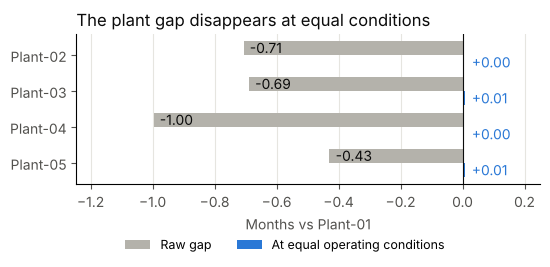

In [31]:
short = lambda t: t.split("T.")[1].rstrip("]")
plots.gap_comparison(raw.params[plant_terms].rename(short), adjusted.params[plant_terms].rename(short),
                     "The plant gap disappears at equal conditions", filename="rca_plant_gaps.png");

In [32]:
print(f"R² of the adjusted model: {adjusted.rsquared:.3f}  ({len(reg):,} batches)")
adjusted.params[conditions].round(3).rename("coefficient (months per unit)")

R² of the adjusted model: 0.782  (176,028 batches)


torque                4.303
temperature          -0.207
ph_distance          -3.898
pressure_distance    -4.912
refractive           20.459
event                 1.995
Name: coefficient (months per unit), dtype: float64

The plant gaps shrink from 0.4–1.0 months to about 0.01, with confidence intervals that include zero.

One coefficient needs care. The **event** coefficient is *positive* (+2). That does not mean the event helps. The straight-line torque term (4.3 months per N·m) overshoots for the very low torque of the event batches, because the real effect flattens below ~11.5 N·m (3.3d), and the event indicator corrects that overshoot. A regression coefficient is only as interpretable as the model's shape is right.

### 3.4c · Where each plant's gap comes from
Outside the May 8 event, each plant's gap to Plant-01 is split into the part due to each operating condition: coefficient × (difference in that plant's average condition). If the parts add up to the actual gap, nothing is left for "the plant itself".

In [33]:
outside = reg[reg["event"] == 0]
base_conditions = ["torque", "temperature", "ph_distance", "pressure_distance", "refractive"]
no_plant = smf.ols("stability ~ " + " + ".join(base_conditions), outside).fit()
breakdown = rootcause.gap_breakdown(outside, no_plant.params, base_conditions, "plant_location", "Plant-01", "stability")
breakdown.round(3)

,torque,temperature,ph_distance,pressure_distance,refractive,explained,actual_gap,unexplained
plant_location,,,,,,,,
Plant-01,0.000,-0.000,-0.000,-0.000,0.000,0.000,0.000,0.000
Plant-02,-0.375,-0.268,-0.039,0.015,-0.075,-0.741,-0.706,0.035
Plant-03,-0.410,-0.192,-0.033,0.005,-0.101,-0.730,-0.689,0.041
Plant-04,-0.149,-0.064,-0.008,0.009,-0.043,-0.255,-0.240,0.015
Plant-05,-0.270,-0.138,-0.013,0.008,-0.043,-0.456,-0.429,0.027


Each plant's gap split into its pieces: torque and temperature are most of it.

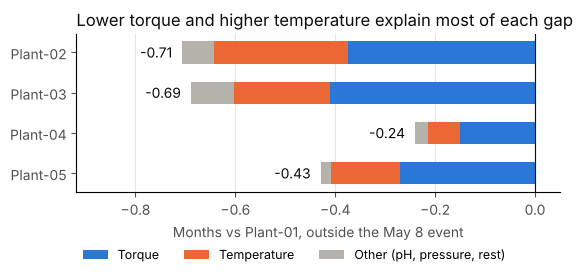

In [34]:
parts = breakdown.drop(index="Plant-01")
pieces = pd.DataFrame({"Torque": parts["torque"], "Temperature": parts["temperature"]})
pieces["Other (pH, pressure, rest)"] = parts["actual_gap"] - pieces.sum(axis=1)
plots.stacked_gaps(pieces, parts["actual_gap"], "Lower torque and higher temperature explain most of each gap",
                   "Months vs Plant-01, outside the May 8 event", filename="rca_plant_gap_breakdown.png");

In [35]:
outside.groupby("plant_location")[["torque", "temperature", "ph_distance", "pressure_distance"]].mean().round(3)

,torque,temperature,ph_distance,pressure_distance
plant_location,,,,
Plant-01,12.049,85.427,0.250,0.150
Plant-02,11.967,86.672,0.259,0.147
Plant-03,11.959,86.321,0.258,0.149
Plant-04,12.016,85.725,0.251,0.148
Plant-05,11.990,86.069,0.253,0.149


### 3.4d · Reactors
After the operating conditions (and the event) are accounted for, does any reactor still stand out? Residual = actual − predicted by the adjusted model without plant.

In [36]:
conditions_only = smf.ols("stability ~ " + " + ".join(conditions), reg).fit()
residual = conditions_only.resid
by_reactor = residual.groupby(reg["reactor"]).mean().sort_values()
print(f"η² of the residual by plant:   {rootcause.eta_squared(residual, reg['plant_location']):.4f}")
print(f"η² of the residual by reactor: {rootcause.eta_squared(residual, reg['reactor']):.4f}")
print(f"reactor mean residuals range from {by_reactor.min():+.3f} to {by_reactor.max():+.3f} months")
load = reg.groupby("reactor").size()
print(f"correlation between a reactor's load (batches) and its mean residual: {load.corr(by_reactor):+.2f}")

η² of the residual by plant:   0.0000
η² of the residual by reactor: 0.0002
reactor mean residuals range from -0.024 to +0.025 months
correlation between a reactor's load (batches) and its mean residual: -0.27


## 3.4 · Conclusions
- **Raw, plants differ a little.** Plant-01 averages 22.1 months, the others 21.1–21.6. The ANOVA p-value is 0, but that only says the differences are not exactly zero. The useful number is η²: plant explains **3.2%** of the variation in stability, reactor 7.6% (2.0% and 2.1% outside the May 8 event: most of the reactor share is the event).
- **At equal operating conditions, plants do not differ.** Adjusting for torque, temperature, pH, pressure, refractive index and the event, the gaps to Plant-01 fall from 0.43–1.00 months to **0.003–0.009 months**, and every confidence interval includes zero. The adjusted model explains R² = 0.78 of the variation.
- **Each plant's gap is explained by how it operates** (outside the event): 95–106% of every gap is accounted for by its average conditions, mostly **torque** (−0.15 to −0.41 months) and **temperature** (−0.06 to −0.27). Plant-02, for example, runs only 0.08 N·m lower torque and 1.2 °C hotter than Plant-01, which costs 0.38 + 0.27 months, and that is essentially its whole 0.71-month gap. Small, consistent differences in operation add up.
- **No reactor stands out** once conditions and the event are accounted for: reactor means of the residual range only from −0.02 to +0.03 months, and reactor explains 0.02% of what is left. Reactor load (the audit found that higher-numbered reactors run more batches) has a weak correlation with these residuals (−0.27), but on differences of a few hundredths of a month: no practical effect.
- **Answer to "are specific plants or reactors responsible?":** only Plant-04 R03, R07, R08 after May 8, through the event (3.1). Otherwise the differences between plants are differences in **operating conditions**, not in the plants. The remedy is a common operating window for every plant, not a plant-specific investigation.
- Note for the technical audience: the event coefficient is positive (+2) only because the straight-line torque term overshoots where torque's real effect flattens (3.3d). It is a correction, not a benefit.

## 3.5 · Synthesis: how much each cause explains, and how to confirm it
Three questions to close the root cause analysis:
1. How many low-stability (Technical-grade) batches does the **May 8 event** explain?
2. For the rest, how much of the gap does each **operating condition** explain?
3. Is there evidence that a better **operating window** works, without relying on a model?

### 3.5a · The May 8 event
Counterfactual: before May 8 the same three reactors produced Technical grade at their normal rate. The *extra* Technical batches are those above that rate.

In [37]:
low_all = y < 20
same_reactors_before = affected & ~after
normal_rate = low_all[same_reactors_before].mean()
event_low = int((low_all & event).sum())
expected_without_event = normal_rate * event.sum()
print(f"Technical-grade batches in the whole dataset: {low_all.sum():,}")
print(f"  from May 8 event batches: {event_low:,} ({event_low / low_all.sum():.0%}); {low_all[event].mean():.0%} of event batches are Technical")
print(f"  expected from those batches at the reactors' normal rate ({normal_rate:.0%}): {expected_without_event:,.0f}")
print(f"  extra Technical batches caused by the event: {event_low - expected_without_event:,.0f}")

Technical-grade batches in the whole dataset: 69,248
  from May 8 event batches: 12,707 (18%); 97% of event batches are Technical
  expected from those batches at the reactors' normal rate (20%): 2,644
  extra Technical batches caused by the event: 10,063


### 3.5b · Outside the event: what separates Technical batches from the rest
The same itemised breakdown as in 3.4c, now between Technical-grade batches and Industrial-or-better batches: their gap in mean stability, split by the difference in each operating condition × its effect.

In [38]:
outside_grade = outside.assign(grade=np.where(outside["stability"] < 20, "Technical", "Industrial or better"))
grade_breakdown = rootcause.gap_breakdown(outside_grade, no_plant.params, base_conditions, "grade",
                                          "Industrial or better", "stability").loc[["Technical"]]
share_of_gap = (grade_breakdown[base_conditions + ["unexplained"]] / grade_breakdown["actual_gap"].iloc[0]).rename(index={"Technical": "share of the gap"})
pd.concat([grade_breakdown, share_of_gap]).round(3)

,torque,temperature,ph_distance,pressure_distance,refractive,explained,actual_gap,unexplained
grade,,,,,,,,
Technical,-1.557,-0.567,-0.373,-0.173,-0.059,-2.73,-3.008,-0.278
share of the gap,0.518,0.189,0.124,0.057,0.020,NaN,NaN,0.093


**Reading 3.5b:** Technical batches are 3.0 months below the rest. Lower torque explains 52% of that gap, higher temperature 19%, pH further from 5.45 12%, pressure 6%, refractive index 2%; 9% is left unexplained.

### 3.5c · Evidence for an operating window, without a model
Some batches already run under good conditions by chance. What happened to them? Windows are taken from the curves of 3.2 and the rules of 3.3 (torque ≥ 12.2 N·m, temperature ≤ 85 °C, pH 5.30–5.60, pressure 2.18–2.38 bar). Outside the May 8 event.

In [39]:
ph_ok = outside["ph_distance"] <= 0.15
p_ok = outside["pressure_distance"] <= 0.10
torque_ok = outside["torque"] >= 12.2
temp_ok = outside["temperature"] <= 85
windows = {
    "torque ≥ 12.2 only": torque_ok,
    "temperature ≤ 85 only": temp_ok,
    "pH 5.30–5.60 only": ph_ok,
    "pressure 2.18–2.38 only": p_ok,
    "torque + temperature": torque_ok & temp_ok,
    "all four conditions": torque_ok & temp_ok & ph_ok & p_ok,
}
window_table = rootcause.window_summary(outside["stability"], windows)
window_table.style.format(
    {"batches": "{:,.0f}", "share_of_production": "{:.1%}", "mean_stability": "{:.1f}", "share_below_20": "{:.1%}"})

,batches,share_of_production,mean_stability,share_below_20
all batches,"167,319",100.0%,21.7,22.9%
torque ≥ 12.2 only,"50,532",30.2%,23.4,1.9%
temperature ≤ 85 only,"71,113",42.5%,22.5,10.7%
pH 5.30–5.60 only,"50,607",30.2%,22.4,12.6%
pressure 2.18–2.38 only,"56,838",34.0%,22.2,15.4%
torque + temperature,"21,591",12.9%,24.4,0.1%
all four conditions,"2,222",1.3%,25.8,0.0%


**Reading the table** (outside the event, 167k batches with all conditions measured; 22.9% Technical overall):
- **Torque ≥ 12.2 N·m alone:** 30% of production already runs there, and only **1.9%** of those batches are Technical, with a mean of 23.4 months. Torque is by far the strongest single lever.
- Temperature, pH or pressure alone each roughly halve the Technical share (10.7%, 12.6%, 15.4%).
- **Torque + temperature together:** 13% of production, **0.1%** Technical, 24.4 months.
- **All four conditions:** 1.3% of production (2,222 batches), **none** Technical, 25.8 months, close to Perfumery grade.

**Caveat:** these batches landed in the window by chance, so this shows association, not a proven effect of moving *other* batches into it. **Torque is a measurement, not a dial:** it reflects how hard the agitator works, which depends on agitator speed and on the mixture's viscosity. Before recommending "higher torque", the plant must say what controls it. Both points go into the confirmation plan.

### 3.5d · Acute vs chronic: which problem is bigger?
The event is the most visible problem, but it is not the only one. Two questions:
1. **How many Technical batches come from the event, and how many from normal operation?**
2. **Is normal operation itself good?** If the event were fixed tomorrow, where would stability be, and how far is that from what the best-run batches already achieve?

In [40]:
normal = ~event                                  # every batch outside the May 8 event (all plants, all quarter)
source = pd.Series(np.where(event, "May 8 event", "Normal operation"), index=y.index)
summary_src = pd.DataFrame({
    "batches": source.value_counts(),
    "Technical batches": low_all.groupby(source).sum(),
    "share of all Technical": low_all.groupby(source).sum() / low_all.sum(),
    "Technical rate": low_all.groupby(source).mean(),
    "mean stability": y.groupby(source).mean(),
    "Perfumery rate": (y >= 25).groupby(source).mean(),
}).loc[["May 8 event", "Normal operation"]]
display(summary_src.style.format({"batches": "{:,.0f}", "Technical batches": "{:,.0f}", "share of all Technical": "{:.0%}",
                                  "Technical rate": "{:.1%}", "mean stability": "{:.2f}", "Perfumery rate": "{:.1%}"}))

week = df["event_time"].dt.to_period("W").dt.start_time
weekly_rate = low_all[normal].groupby(week[normal]).mean()
print(f"Normal operation, Technical rate per week: {weekly_rate.min():.1%} to {weekly_rate.max():.1%} "
      f"(before May 8 {low_all[normal & ~after].mean():.1%}, from May 8 {low_all[normal & after].mean():.1%})")
print(f"Normal operation reaching 24 months (middle of the 18-30 specification): {(y[normal] >= 24).mean():.1%}")

,batches,Technical batches,share of all Technical,Technical rate,mean stability,Perfumery rate
May 8 event,"13,145","12,707",18%,96.7%,18.61,0.0%
Normal operation,"246,055","56,541",82%,23.0%,21.69,7.1%


Normal operation, Technical rate per week: 22.3% to 23.7% (before May 8 22.9%, from May 8 23.0%)
Normal operation reaching 24 months (middle of the 18-30 specification): 14.5%


**Headroom.** Normal operation compared with the batches of 3.5c that already run in the operating window (rows of the 3.5c table).

,share_of_production,mean_stability,share_below_20,gain vs normal (months)
normal operation,100.0%,21.69,23.0%,+0.00
torque + temperature,12.9%,24.35,0.1%,+2.67
all four conditions,1.3%,25.82,0.0%,+4.13


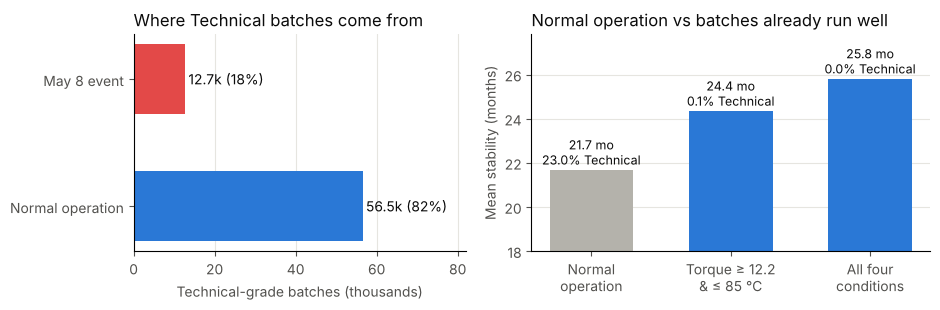

In [41]:
levels = pd.concat([pd.DataFrame({"share_of_production": [1.0], "mean_stability": [y[normal].mean()],
                                  "share_below_20": [low_all[normal].mean()]}, index=["normal operation"]),
                    window_table.loc[["torque + temperature", "all four conditions"]][["share_of_production", "mean_stability", "share_below_20"]]])
levels["gain vs normal (months)"] = levels["mean_stability"] - levels.loc["normal operation", "mean_stability"]
display(levels.style.format({"share_of_production": "{:.1%}", "mean_stability": "{:.2f}", "share_below_20": "{:.1%}",
                             "gain vs normal (months)": "{:+.2f}"}))

chart = levels.rename(index={"normal operation": "Normal\noperation", "torque + temperature": "Torque ≥ 12.2\n& ≤ 85 °C",
                             "all four conditions": "All four\nconditions"})
plots.acute_vs_chronic(summary_src["Technical batches"], chart, filename="rca_acute_vs_chronic.png");

**Reading 3.5d**
- **Two problems of different nature.** The May 8 event is **acute**: sudden, local (3 of 37 reactors) and easy to see; it produces **18%** of the Technical batches. Normal operation is a **chronic** problem: it produces the other **82%** (56,541 batches), in every plant.
- **The chronic rate does not move.** Outside the event, about **23%** of batches are Technical in every week, before and after May 8. It is the normal state of the process, not a failure, which is why nobody notices it: everything runs within specification.
- **Normal operation sits low in the specification.** Mean 21.7 months on an 18–30 scale; only 7% reach Perfumery and 15% reach 24 months, the middle of the range.
- **The headroom is large.** The 13% of batches that already run at torque ≥ 12.2 N·m and ≤ 85 °C average **24.4 months (+2.7)** with 0.1% Technical; the 1.3% that meet all four conditions average **25.8 months (+4.1)** with none Technical.
- **For the business:** fixing the event removes ~190 extra Technical batches a day, but the larger prize is in normal operation. Caveat as in 3.5c: these batches landed in the window by chance, so the gain must be confirmed by the controlled trial before it is promised.

### 3.5e · Root-cause statement

**For the business:**
**Two problems, of different size and nature** (3.5d): an *acute* event that produces 18% of the Technical-grade batches, and a *chronic* one, normal operation in every plant, that produces the other 82% (about 23% of batches are Technical in every week).

1. **One event explains the sharpest problem.** On the night of 7–8 May 2023, three reactors in Plant-04 (R03, R07, R08) lost about 3.3 months of shelf life overnight and have not recovered. It coincides with a large drop in mixing torque. It accounts for about 18% of all Technical-grade batches and ~10,000 extra Technical batches over 53 days, roughly 190 per day while it continues.
2. **The chronic problem: everywhere else, four operating conditions explain most of the variation**, in this order: mixing torque (more is better), reaction temperature (cooler is better), pH (best around 5.45) and vessel pressure (best around 2.3 bar). Together they explain 78% of batch-to-batch differences.
3. **The statement's normal ranges are too wide to protect stability.** Batches at the edges of the "normal" pH or pressure range lose 1.3–1.9 months, and the event itself happened at a torque inside the normal range.
4. **No plant or reactor is intrinsically worse.** At equal operating conditions, plants are within hours of each other; their differences come from how they run the process (Plant-02, for example, runs ~1 °C hotter at slightly lower torque).
5. **A separate data-quality issue in Plant-04:** all sentinel codes and all Fahrenheit readings come from its data acquisition. It does not affect stability, but it should be fixed.

**Recommendations:**
- **Investigate May 7–8 in Plant-04** (see the questions below) and restore the previous operating state of R03, R07, R08.
- **Monitor daily mean torque with a control chart** (limits from a stable period). This event would have raised an alarm on day one.
- **Run a small controlled trial** of a tighter operating window (torque ≥ ~12.2 N·m, temperature ≤ ~85 °C, pH 5.3–5.6, pressure 2.2–2.4 bar) before changing standard procedures. Batches that already run in it are almost never Technical grade.
- **Fix Plant-04's data logging** (sentinel codes, °F readings).

### 3.5f · Confirmation plan
The data shows associations; these steps would confirm causes.

| What to confirm | How | Who |
|---|---|---|
| What changed in Plant-04 R03, R07, R08 on the night of May 7–8 | Questions to the plant (below) | Plant-04 operations, maintenance, purchasing |
| What controls mixing torque | Ask engineering: agitator speed setpoint, motor, viscosity of the feed | Process engineering |
| That lower temperature and a tighter pH/pressure window raise stability | Designed experiment: a few batches at two temperatures × two pH levels in one reactor, everything else fixed; measure stability | Process engineering + Quality lab |
| That the window helps in every plant | Pilot in one reactor per plant for a few weeks, compare against the control chart | Plant managers |
| That logging is fixed | Check for sentinel codes and unit mix-ups after the fix | Plant-04 IT / automation |

**Questions for the plant about May 7–8**
What the data says: from midnight on May 8, three reactors (R03, R07, R08) of Plant-04 produce batches with ~1.2 N·m lower mixing torque, slightly higher pH and density, and ~3.3 months less shelf life; the other five Plant-04 reactors are unaffected.

1. **Maintenance:** was any work done on R03, R07 or R08 on May 7–8, in particular on the agitators, impellers, drive motors or gearboxes? Were parts replaced?
2. **Settings:** did anything change in the recipe, the agitator speed setpoint or the control software (PLC, DCS) for these reactors around midnight on May 7–8?
3. **Raw materials:** did these three reactors start using a new lot or a new supplier of any raw material or catalyst on May 8? Do they share a feed tank or line that the other five do not?
4. **What makes them different:** what do R03, R07 and R08 have in common that the other Plant-04 reactors do not (age, model, operating crew, product variant, location)?
5. **Torque:** what controls mixing torque in these reactors, the agitator speed setpoint or the viscosity of the mixture? Is a drop of ~10% plausible without anyone noticing?
6. **Still ongoing:** is the situation still the same today? Has anything been done since?
7. **Shipped product:** have batches produced in these reactors since May 8 been shipped or released as Industrial grade? Their predicted shelf life is ~18.6 months, and 97% fall below 20 months.
8. **Data:** can the plant share maintenance logs, setpoint histories and raw-material lot records for April–June, so the timing can be matched batch by batch?

## Phase 3 · Summary
| Hypothesis (audit) | Verdict |
|---|---|
| H1: May 8 event in Plant-04 R03/R07/R08 | **Confirmed** as the only localized change: −3.26 months net, torque −4 SD; cause to be confirmed by the plant |
| H2: torque is the main driver | **Confirmed**: largest effect in every method (curves, tree, SHAP, regression) |
| H3: higher temperature lowers stability | **Confirmed**: −0.21 months per °C, second driver |
| H4: pH outside its window lowers stability | **Confirmed and refined**: peaked at ~5.45, matters inside the normal range too |
| H5: low pressure in Plant-02 | **Reframed**: the low end of a peaked pressure effect (optimum ~2.3 bar), not a Plant-02 problem |
| New: acute vs chronic | Normal operation produces **82%** of Technical batches (23% Technical rate in every week); batches already in the window average 24.4 months vs 21.7 |
| D1: Plant-04 data acquisition | **Confirmed**, unrelated to stability |